# Saúde e Meio Ambiente - Doenças Cardiovasculares - Data Analysis

## Data Import

In [60]:
import pandas as pd

In [61]:
# Creating main DataFrame
month_dict = {
    "Janeiro": "/01",
    "Fevereiro": "/02",
    "Março": "/03",
    "Abril": "/04",
    "Maio": "/05",
    "Junho": "/06",
    "Julho": "/07",
    "Agosto": "/08",
    "Setembro": "/09",
    "Outubro": "/10",
    "Novembro": "/11",
    "Dezembro": "/12",
}
years = [2020, 2021, 2022, 2023, 2024]
all_datas = []
for year in years:
    for key, value in month_dict.items():
        all_datas.append(f'{year}{value}')
df = pd.DataFrame({'data': all_datas})

In [62]:
# Import Área Queimada
df_list = []
for year in years: 
    path = f'data\Fogo • Mensal por classe • {year}.csv'
    _df = pd.read_csv(path, sep=',', names=['data','Área Queimada'], skiprows=1)
    _df['data'] = _df['data'].map(lambda x: f'{year}{month_dict[x]}')
    df_list.append(_df)
_df = pd.concat(df_list, ignore_index=True)
df = pd.merge(df, _df, on = 'data', how='inner')

In [63]:
# Import Perda de Vegetação
primary_veg_sup = []
secondary_veg_sup = []
for year in years: 
    path = f'data\Perda de Vegetação Nativa • Annual por classe • {year}.csv'
    _df = pd.read_csv(path, sep=',', names=['vegetation','values'], skiprows=1)
    primary_veg_sup+=12*[_df.loc[_df['vegetation'] == 'Primary Vegetation Suppression', 'values'].values[0]]
    secondary_veg_sup+=12*[_df.loc[_df['vegetation'] == 'Secondary Vegetation Suppression', 'values'].values[0]]
_df = pd.DataFrame({
    'data': all_datas,
    'Supressão de Vegetação\n Primária': primary_veg_sup,
    'Supressão de Vegetação\n Secundária': secondary_veg_sup
})
df = pd.merge(df, _df, on = 'data', how='inner')

In [64]:
# Import Material Particulado MP2.5
# _df = pd.read_csv(r'data\Série temporal dos valores - Material particulado fino mensal (MP2.5) - 2003 - 2024.csv', sep=',').iloc[:, -5:]
# mp2_5_values = [] 
# for column in _df.columns:
#     mp2_5_values+=list(_df[column])
# _df = pd.DataFrame({
#     'data': all_datas,
#     'Material Particulado 2.5': mp2_5_values,
# })
# df = pd.merge(df, _df, on = 'data', how='inner')

In [65]:
# Import Material Particulado MP2.5
_df = pd.read_csv(r'data\Série temporal dos valores - Material particulado inalável mensal (MP10) - 2003 - 2024.csv', sep=',').iloc[:, -5:]
mp10_values = [] 
for column in _df.columns:
    mp10_values+=list(_df[column])
_df = pd.DataFrame({
    'data': all_datas,
    'Material Particulado 10': mp10_values,
})
df = pd.merge(df, _df, on = 'data', how='inner')

In [66]:
# Import Precipitação Mensal
_df = pd.read_csv(r'data\Série temporal dos valores - Precipitação mensal - 1985 - 2024.csv', sep=',').iloc[:, -5:]
precipitation_values = [] 
for column in _df.columns:
    precipitation_values+=list(_df[column])
_df = pd.DataFrame({
    'data': all_datas,
    'Precipitação': precipitation_values,
})
df = pd.merge(df, _df, on = 'data', how='inner')


In [67]:
# Import Precipitação Mensal
_df = pd.read_csv(r'data\TEMPERATURA MEDIA.csv', sep=',').iloc[:, -5:]
temperature_values = [] 
for column in _df.columns:
    temperature_values+=list(_df[column])
_df = pd.DataFrame({
    'data': all_datas,
    'Temperatura': temperature_values,
})
df = pd.merge(df, _df, on = 'data', how='inner')


In [68]:
# Import Vegetação Urbana
intraurban_veg = []
periurban_veg = []
non_veg = []
for year in years: 
    path = rf'data\Urbano • Vegetação urbana por classe • {year}.csv'
    _df = pd.read_csv(path, sep=',', names=['vegetation_class','values'], skiprows=1)
    # intraurban_veg+=12*[_df.loc[_df['vegetation_class'] == 'Vegetação intraurbana', 'values'].values[0]]
    # periurban_veg+=12*[_df.loc[_df['vegetation_class'] == 'Maciços vegetais urbanos e vegetação periurbana', 'values'].values[0]]
    non_veg+=12*[_df.loc[_df['vegetation_class'] == 'Área urbanizada não vegetada', 'values'].values[0]]
_df = pd.DataFrame({
    'data': all_datas,
    # 'Vegetação Intraurbana': intraurban_veg,
    # 'Vegetação Periurbana': periurban_veg,
    'Área Urbanizada não Vegetada': non_veg,
})
df = pd.merge(df, _df, on = 'data', how='inner')

In [69]:
# Import Doenças Cardiovasculares - Variável Objetivo
_df = pd.read_csv(r'data\DOENÇAS CARDIOVASCULARES.csv', sep=';', names=['data','Doenças Cardiovasculares'])
df = pd.merge(df, _df, on = 'data', how='inner')

## Data Exploration and Analysis

In [75]:
from seaborn import pairplot, heatmap, diverging_palette, regplot
from numpy import zeros_like, triu_indices_from
import matplotlib.pyplot as plt
from sklearn.preprocessing import PowerTransformer

In [71]:
data_columns = list(df.columns)[1:]
data_columns

['Área Queimada',
 'Supressão de Vegetação\n Primária',
 'Supressão de Vegetação\n Secundária',
 'Material Particulado 10',
 'Precipitação',
 'Temperatura',
 'Área Urbanizada não Vegetada',
 'Doenças Cardiovasculares']

In [ ]:
# Appending Yeo-Johnson ZnAlMg to Dataframe (for analysis)
pt = PowerTransformer(method='yeo-johnson', standardize=False)
df[f'y-j(Área Queimada)'] = pt.fit_transform(df[['Área Queimada']]).flatten()
df[f'y-j(Material Particulado 10)'] = pt.fit_transform(df[['Material Particulado 10']]).flatten()
y_j_columns = [
    f'y-j(Área Queimada)',
    f'y-j(Material Particulado 10)',
    'Doenças Cardiovasculares'
]

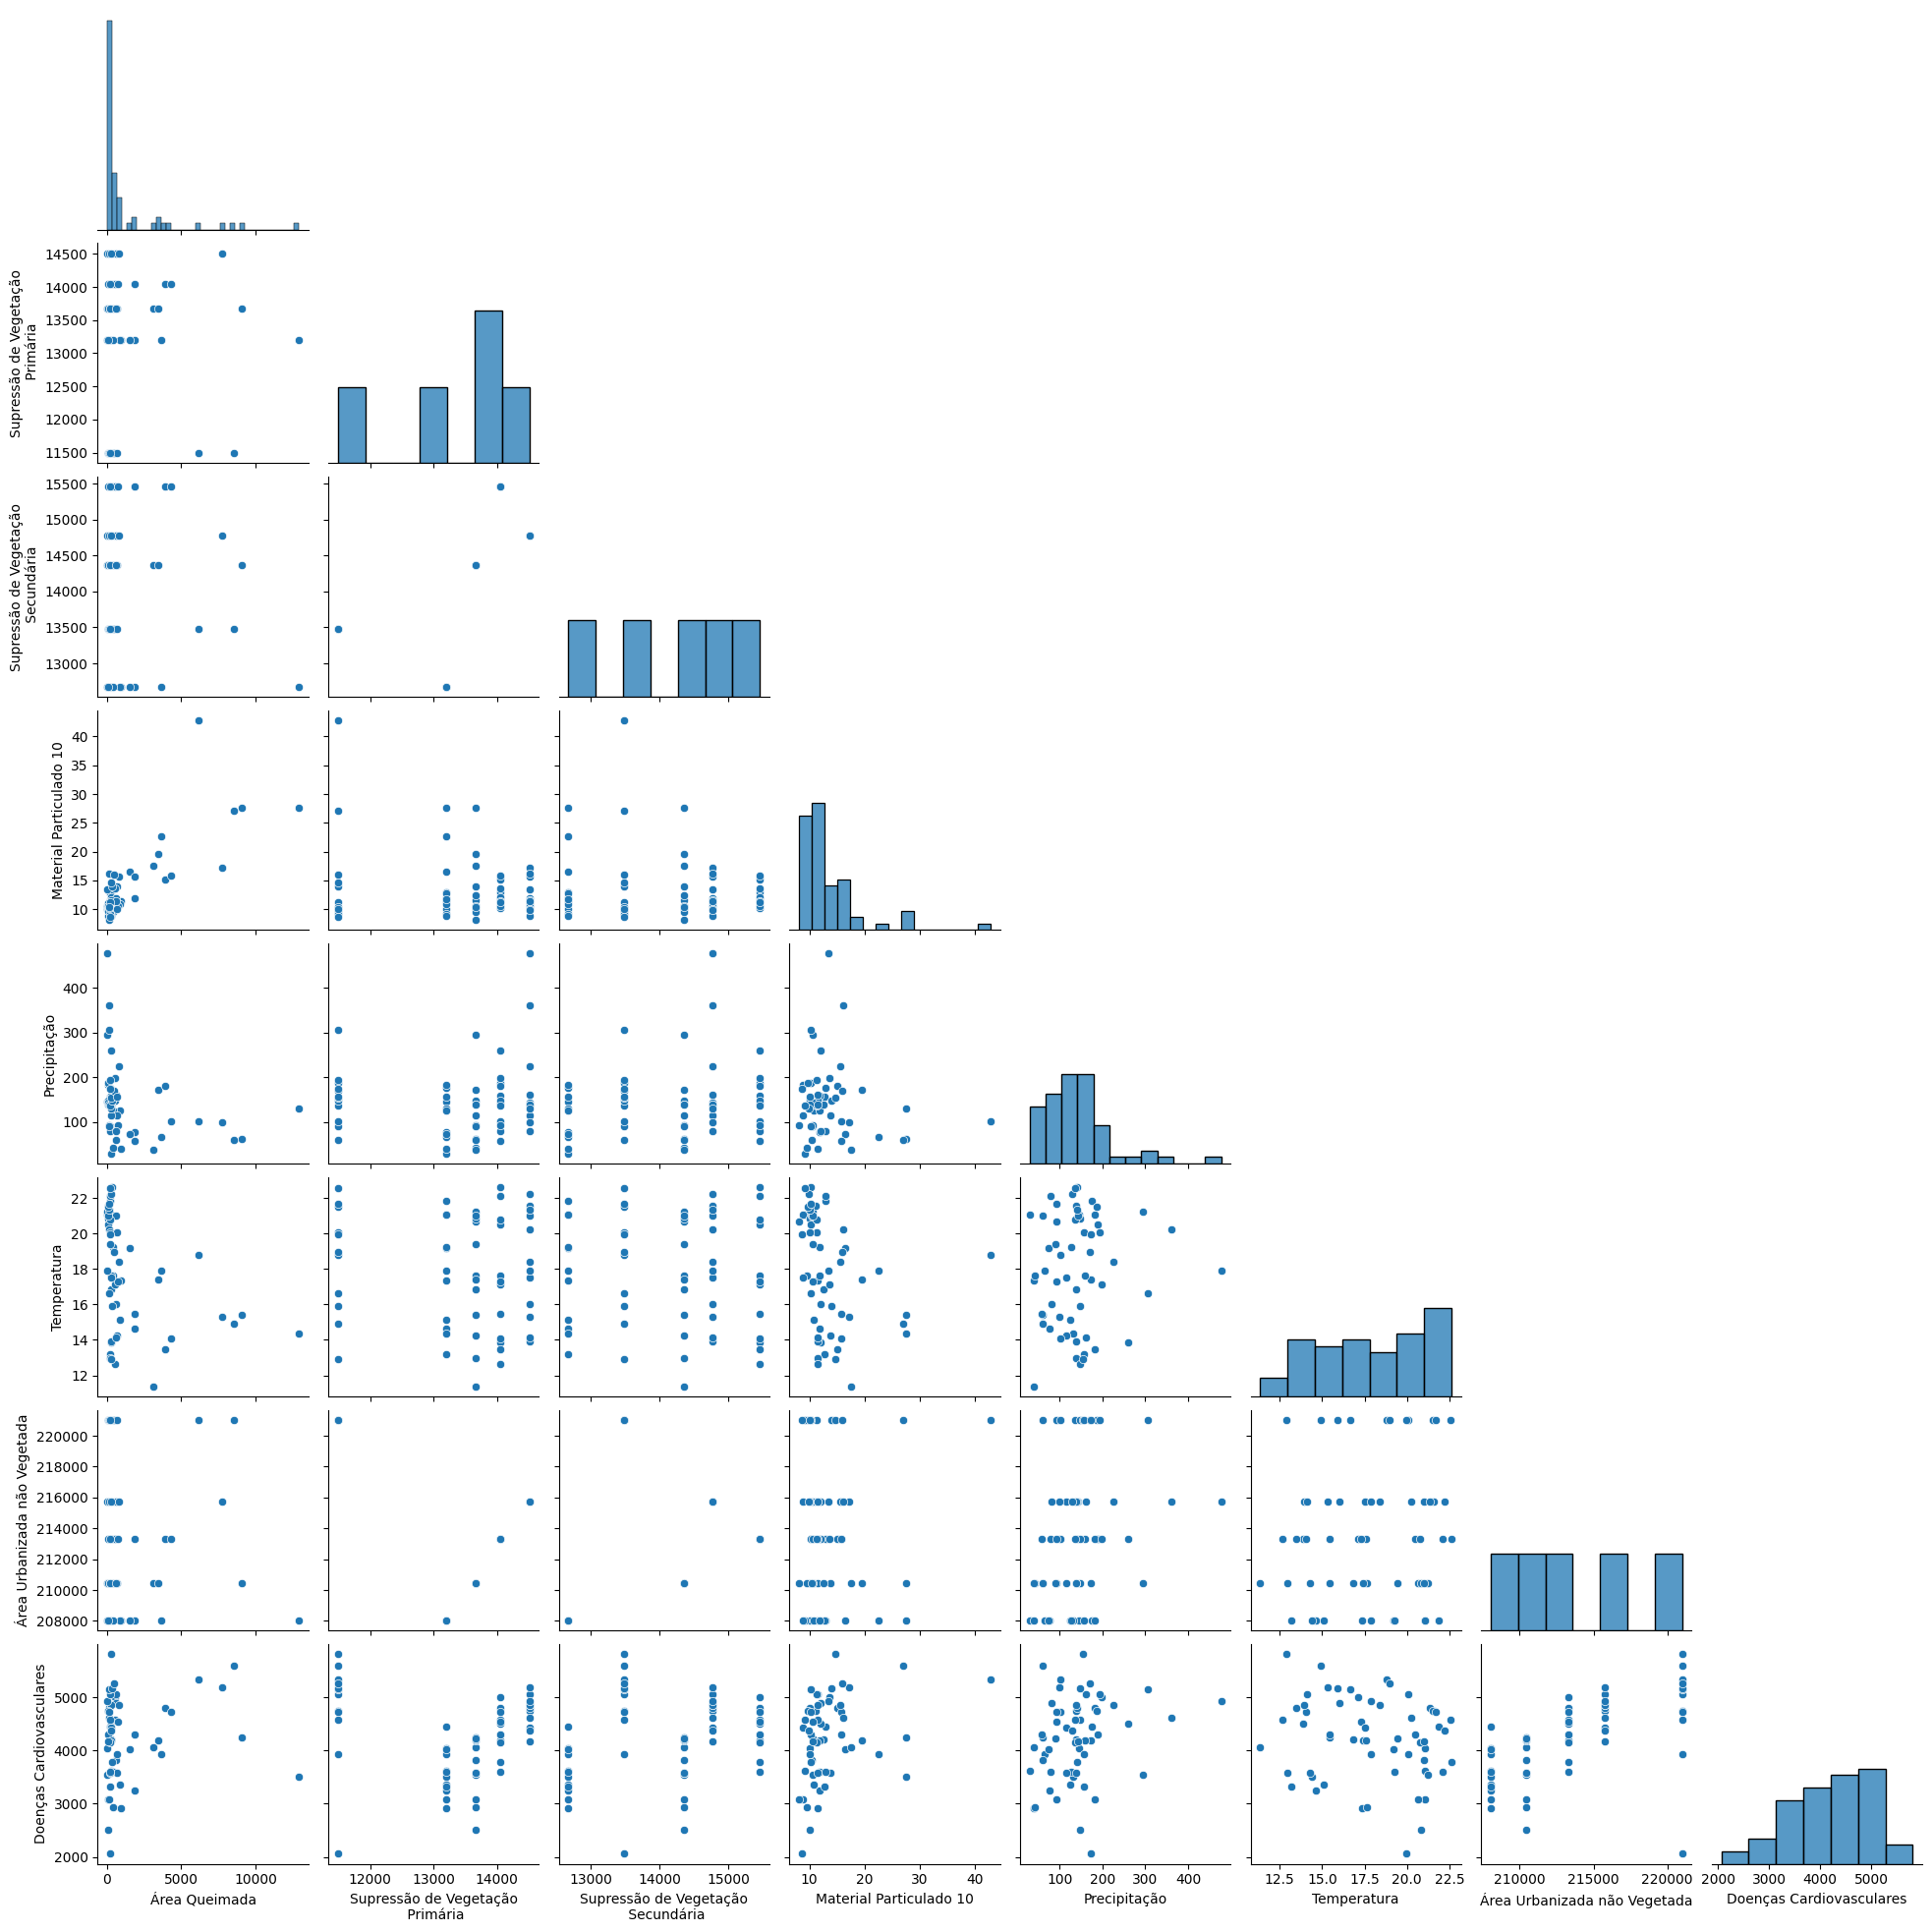

In [88]:
# Correlation Pairplot
pairplot(df[data_columns], corner=True)

<Axes: >

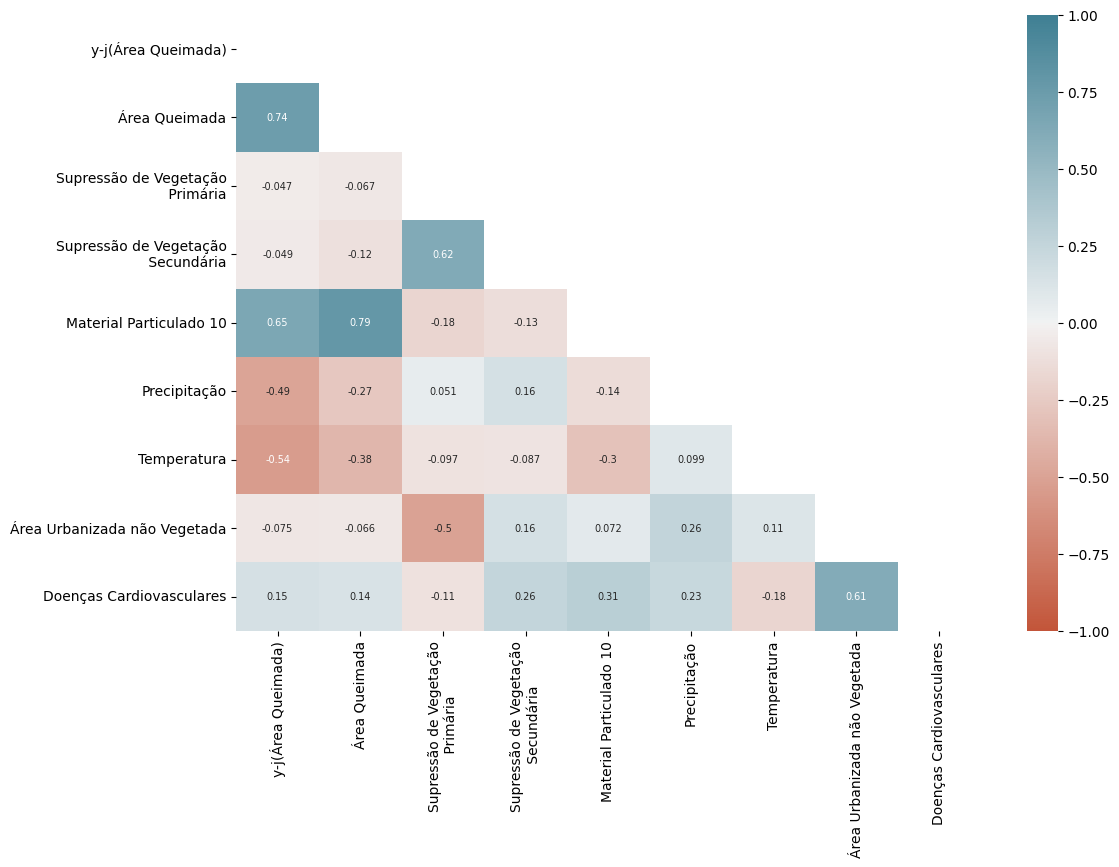

In [85]:
# Correlation Heatmap
fig, ax = plt.subplots(figsize=(12,8))
corrmat = df[[f'y-j(Área Queimada)']+data_columns].corr()
mask= zeros_like(corrmat)
mask[triu_indices_from(mask)] = True
heatmap(corrmat,
            vmax=1, vmin=-1,
            annot=True, annot_kws={'fontsize':7},
            mask=mask,
            cmap=diverging_palette(20,220,as_cmap=True), ax=ax)

<Axes: xlabel='Material Particulado 10', ylabel='Doenças Cardiovasculares'>

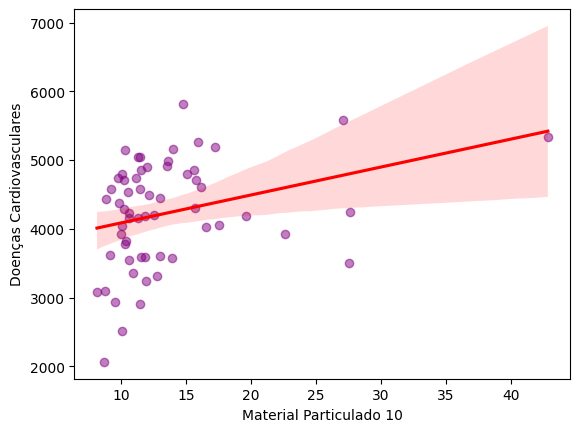

In [80]:
regplot_kws = {
    "scatter_kws": {"color": "purple", "alpha": 0.5}, 
    "line_kws": {"color": "red"}
}
regplot(x=df['Material Particulado 10'], y=df['Doenças Cardiovasculares'], **regplot_kws)

<Axes: xlabel='Área Urbanizada não Vegetada', ylabel='Doenças Cardiovasculares'>

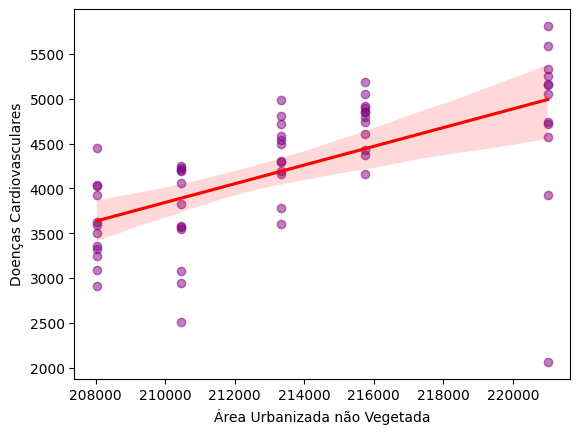

In [81]:
regplot_kws = {
    "scatter_kws": {"color": "purple", "alpha": 0.5}, 
    "line_kws": {"color": "red"}
}
regplot(x=df['Área Urbanizada não Vegetada'], y=df['Doenças Cardiovasculares'], **regplot_kws)

<Axes: xlabel='y-j(Área Queimada)', ylabel='Doenças Cardiovasculares'>

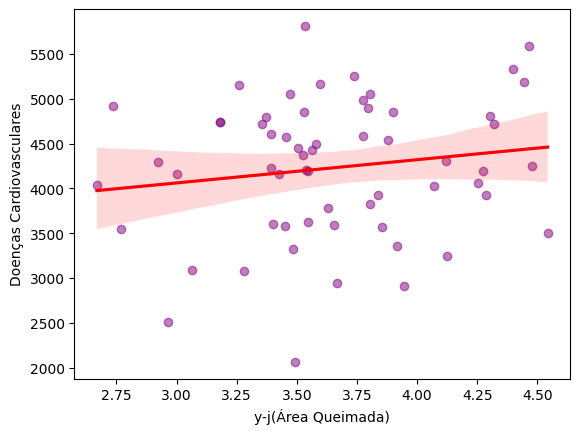

In [82]:
regplot_kws = {
    "scatter_kws": {"color": "purple", "alpha": 0.5}, 
    "line_kws": {"color": "red"}
}
regplot(x=df[f'y-j(Área Queimada)'], y=df['Doenças Cardiovasculares'], **regplot_kws)